# 1985 — Boltzmann Machines → Restricted Boltzmann Machines

**Papers:** Ackley, Hinton & Sejnowski, *"A Learning Algorithm for Boltzmann Machines"* (1985); Smolensky's *Harmonium* (1986); Hinton, *"Training Products of Experts by Minimizing Contrastive Divergence"* (2002).

A Boltzmann machine is a **stochastic** Hopfield network with hidden units that defines a probability distribution $p(v,h) \propto e^{-E(v,h)}$. Fully connected ones are very slow to train, so the **Restricted** BM removes visible–visible and hidden–hidden connections:

$$E(v,h) = -a^\top v - b^\top h - v^\top W h, \qquad p(h_j{=}1\mid v)=\sigma(b_j + v^\top W_{:j}), \quad p(v_i{=}1\mid h)=\sigma(a_i + W_{i:}h)$$

The log-likelihood gradient is $\langle v h^\top\rangle_{\text{data}} - \langle v h^\top\rangle_{\text{model}}$. **Contrastive divergence (CD-k)** approximates the model term with $k$ steps of Gibbs sampling started at the data. Stacked RBMs gave the 2006 *Deep Belief Network* that restarted deep learning.

Pure NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
rng = np.random.default_rng(0)
sigmoid = lambda z: 1 / (1 + np.exp(-z))

d = load_digits()
V = (d.data / 16.0 > 0.4).astype(float)   # binarise the 8x8 digits -> 64 visible units
print("data:", V.shape)

data: (1797, 64)


In [2]:
class RBM:
    def __init__(self, n_vis, n_hid):
        self.W = rng.normal(0, 0.01, (n_vis, n_hid))
        self.a = np.zeros(n_vis)   # visible bias
        self.b = np.zeros(n_hid)   # hidden bias

    def p_h(self, v): return sigmoid(v @ self.W + self.b)
    def p_v(self, h): return sigmoid(h @ self.W.T + self.a)
    def sample(self, p): return (rng.random(p.shape) < p).astype(float)

    def free_energy(self, v):
        return -v @ self.a - np.logaddexp(0, v @ self.W + self.b).sum(1)

    def cd_step(self, v0, k=1, lr=0.05):
        ph0 = self.p_h(v0)
        h = self.sample(ph0)
        for _ in range(k):                       # k steps of block Gibbs sampling
            vk = self.sample(self.p_v(h))
            phk = self.p_h(vk)
            h = self.sample(phk)
        n = len(v0)
        self.W += lr * (v0.T @ ph0 - vk.T @ phk) / n          # <vh>_data - <vh>_model
        self.a += lr * (v0 - vk).mean(0)
        self.b += lr * (ph0 - phk).mean(0)
        return ((v0 - self.p_v(ph0)) ** 2).mean()            # reconstruction error (a proxy)

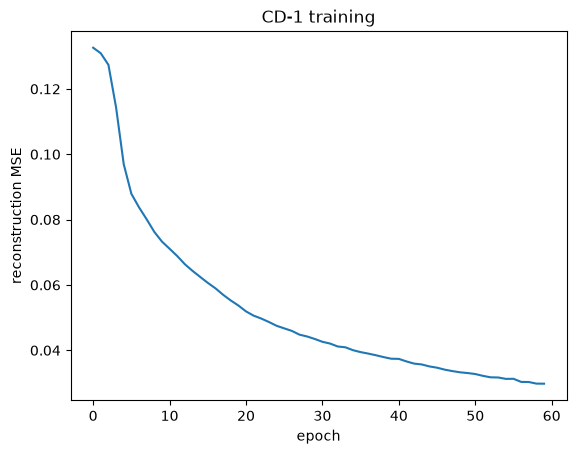

mean free energy: data = -88.68 | random noise = -9.87


In [3]:
rbm = RBM(64, 64)
errs = []
for epoch in range(60):
    perm = rng.permutation(len(V)); e = []
    for i in range(0, len(V), 32):
        e.append(rbm.cd_step(V[perm[i:i + 32]], k=1, lr=0.1))
    errs.append(np.mean(e))
plt.plot(errs); plt.xlabel("epoch"); plt.ylabel("reconstruction MSE"); plt.title("CD-1 training"); plt.show()
print("mean free energy: data =", rbm.free_energy(V).mean().round(2), "| random noise =", rbm.free_energy(rng.integers(0, 2, V.shape).astype(float)).mean().round(2))

## Learned features (columns of W) and reconstructions
Lower free energy for real digits than for noise means the RBM assigns them higher probability.

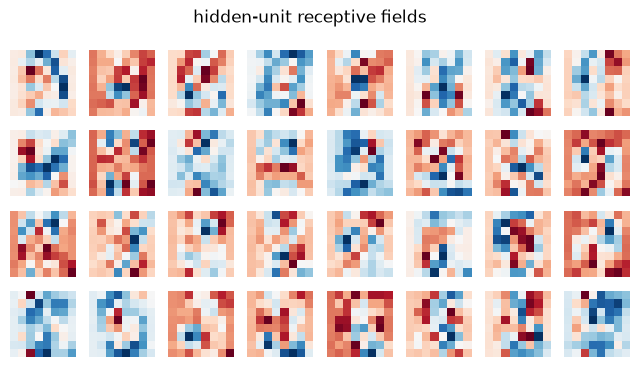

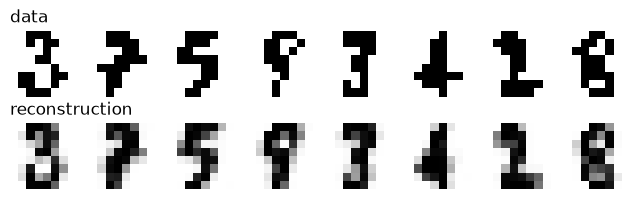

In [4]:
fig, axes = plt.subplots(4, 8, figsize=(8, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(rbm.W[:, i].reshape(8, 8), cmap="RdBu"); ax.axis("off")
plt.suptitle("hidden-unit receptive fields"); plt.show()

idx = rng.choice(len(V), 8, replace=False)
recon = rbm.p_v(rbm.p_h(V[idx]))
fig, axes = plt.subplots(2, 8, figsize=(8, 2.2))
for j in range(8):
    axes[0, j].imshow(V[idx[j]].reshape(8, 8), cmap="gray_r"); axes[1, j].imshow(recon[j].reshape(8, 8), cmap="gray_r")
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[0, 0].set_title("data", loc="left"); axes[1, 0].set_title("reconstruction", loc="left"); plt.show()

## Dreaming: long Gibbs chains from noise

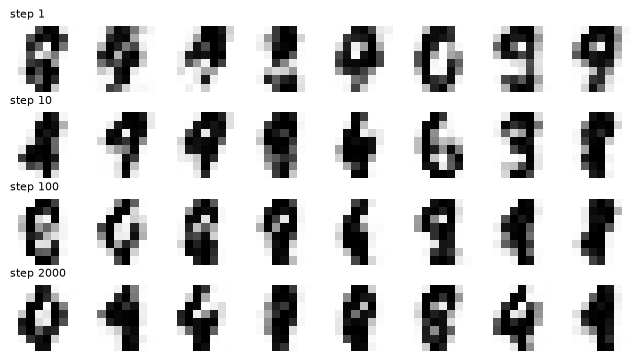

In [5]:
v = rng.integers(0, 2, (8, 64)).astype(float)
snaps = []
for t in range(1, 2001):
    v = rbm.sample(rbm.p_v(rbm.sample(rbm.p_h(v))))
    if t in (1, 10, 100, 2000): snaps.append(rbm.p_v(rbm.p_h(v)))
fig, axes = plt.subplots(4, 8, figsize=(8, 4.3))
for r, (s, t) in enumerate(zip(snaps, (1, 10, 100, 2000))):
    for j in range(8):
        axes[r, j].imshow(s[j].reshape(8, 8), cmap="gray_r"); axes[r, j].axis("off")
    axes[r, 0].set_title(f"step {t}", loc="left", fontsize=8)
plt.show()

## Features are useful for classification
A logistic regression on hidden probabilities vs. raw pixels — the "unsupervised pre-training" idea.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
print("raw pixels :", cross_val_score(LogisticRegression(max_iter=2000), V, d.target, cv=3).mean().round(3))
print("RBM hidden :", cross_val_score(LogisticRegression(max_iter=2000), rbm.p_h(V), d.target, cv=3).mean().round(3))

raw pixels : 0.889
RBM hidden : 0.897
